# Partie III — RNN, LSTM, GRU et Seq2Seq

**Projet de fin de module — Deep Learning — EMSI Casablanca, 2025–2026**

> Modélisation de séquences et génération / traduction sur données textuelles réelles.

Cette troisième partie du projet traite les **données séquentielles**. Contrairement aux
données tabulaires (Partie I, MLP) et aux images (Partie II, CNN), une séquence
$(x_1, x_2, \dots, x_T)$ possède un **ordre** et une **longueur variable** : le sens d'un
mot, ou la valeur future d'un signal, dépend de ce qui précède. L'architecture doit donc
porter une **mémoire** du contexte. Le travail est organisé en deux volets complémentaires,
conformément au cahier des charges (§7) :

**Volet A — Modélisation de langage** *(« The Time Machine », niveau caractère)*
1. fondements probabilistes d'un modèle de langage et perplexité ;
2. préparation des données (tokenisation, vocabulaire, mini-lots séquentiels) ;
3. implémentation d'un RNN, d'un LSTM et d'un GRU ;
4. BPTT et illustration expérimentale du **gradient clipping** ;
5. comparaison des trois cellules récurrentes.

**Volet B — Système Seq2Seq** *(traduction anglais → français, corpus fra-eng / Tatoeba)*
6. préparation d'un corpus parallèle (tokens spéciaux, padding, masquage, mini-lots) ;
7. architecture encodeur–décodeur récurrente et teacher forcing ;
8. entraînement avec perte masquée ;
9. décodage **glouton** et **beam search**, évaluation par **BLEU**.

Suivent l'analyse critique, la réponse à la question de synthèse, la **question transversale
finale** reliant MLP / CNN / RNN (§8), et la vérification de conformité.

*Le notebook reprend les conventions des Parties I et II : code commenté, figures
enregistrées dans `outputs/rnn/`, et après chaque expérience une interprétation reliant les
résultats à la théorie.*

## 0. Configuration de l'environnement

Imports, chemins relatifs (cohérents avec l'arborescence du projet), détection du *device* et
fixation de la graine aléatoire pour la reproductibilité.

In [1]:
import os, re, math, time, random, zipfile, collections, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# --- Chemins (basés sur l'arborescence du projet) ---
DATA_LM  = Path('../data/rnn')        # corpus Time Machine (modèle de langage)
DATA_MT  = Path('../data/seq2seq')    # corpus parallèle fra-eng (traduction)
OUTPUT_DIR = Path('../outputs/rnn')   # figures, tableaux, modèles
for d in (DATA_LM, DATA_MT, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Device (GPU si disponible, sinon CPU) ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device actif :', device)

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def count_parameters(model):
    """Nombre de paramètres entraînables d'un modèle."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

plt.rcParams['figure.dpi'] = 110

Device actif : cpu


# Volet A — Modélisation de langage

Corpus : **« The Time Machine »** (H. G. Wells), modélisé au **niveau caractère**. Ce choix,
classique, est idéal pour illustrer la perplexité et le gradient clipping : le texte forme une
**séquence continue longue** (≈ 170 000 caractères), ce qui sollicite réellement la mémoire
récurrente et la rétropropagation à travers le temps.

## 1. Introduction théorique : modèle de langage et perplexité

### 1.1 Objectif probabiliste et règle de chaîne

Un **modèle de langage** attribue une probabilité à une suite de tokens
$(x_1, \dots, x_T)$. Par la **règle de chaîne** :

$$ P(x_1, \dots, x_T) \;=\; \prod_{t=1}^{T} P(x_t \mid x_1, \dots, x_{t-1}). $$

L'idée fondatrice est simple : **modéliser une phrase entière revient à savoir prédire le
prochain token connaissant le passé**. Toute la difficulté réside dans la représentation de ce
passé $x_{<t}$. C'est précisément le rôle de l'**état caché** d'un RNN : résumer, sous forme
vectorielle, ce qui a été observé jusqu'au pas $t$.

### 1.2 Limites des n-grammes

Les modèles de Markov d'ordre $n-1$ approximent
$P(x_t\mid x_{<t}) \approx P(x_t\mid x_{t-n+1}, \dots, x_{t-1})$. Simples et rapides, ils
souffrent d'une **explosion combinatoire**, d'une **sparsité** sévère et d'une incapacité à
capturer les **dépendances longues**. Les réseaux récurrents lèvent ces limites en
apprenant une représentation **continue** et **partagée** du contexte.

### 1.3 Perplexité

La qualité d'un modèle de langage se mesure par la **perplexité** :

$$ \mathrm{PPL} \;=\; \exp\!\Big( -\frac{1}{T}\sum_{t=1}^{T} \log P(x_t \mid x_{<t}) \Big). $$

C'est l'exponentielle de l'entropie croisée moyenne par token. **Interprétation** : la
perplexité est le *nombre moyen de choix équiprobables* hésités par le modèle à chaque pas.
Une perplexité de 1 correspond à un modèle parfait ; une perplexité égale à la taille du
vocabulaire correspond au hasard. **Plus elle est faible, meilleur est le modèle.**

## 2. Préparation des données (Time Machine, niveau caractère)

Pipeline : téléchargement (avec mise en cache locale et repli hors-ligne), nettoyage
(on ne conserve que les lettres et les espaces, en minuscules), **tokenisation au niveau
caractère**, construction du **vocabulaire**, puis génération de **mini-lots séquentiels**.

In [2]:
def load_time_machine():
    """Télécharge (et met en cache) le texte de The Time Machine."""
    path = DATA_LM / 'timemachine.txt'
    if not path.exists():
        urls = ['http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt',
                'https://www.gutenberg.org/files/35/35-0.txt']
        for u in urls:
            try:
                urllib.request.urlretrieve(u, path)
                break
            except Exception as e:
                print('Échec téléchargement', u, ':', e)
    return path.read_text(encoding='utf-8')

raw_text = load_time_machine()
# Nettoyage : uniquement lettres + espaces, en minuscules
clean_text = re.sub('[^A-Za-z]+', ' ', raw_text).strip().lower()
char_tokens = list(clean_text)

print('Caractères bruts   :', len(raw_text))
print('Caractères nettoyés:', len(char_tokens))
print('Extrait :', repr(clean_text[:70]))

Caractères bruts   : 178979
Caractères nettoyés: 173427
Extrait : 'the time machine by h g wells i the time traveller for so it will be c'


In [3]:
class Vocab:
    """Vocabulaire : correspondance token <-> indice, avec token spécial <unk>."""
    def __init__(self, tokens, min_freq=0, reserved=None):
        reserved = reserved or []
        counter = collections.Counter(tokens)
        self._token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        # <unk> en indice 0, puis les tokens réservés, puis par fréquence décroissante
        self.idx_to_token = list(dict.fromkeys(['<unk>'] + reserved))
        for tok, freq in self._token_freqs:
            if freq < min_freq:
                break
            if tok not in self.idx_to_token:
                self.idx_to_token.append(tok)
        self.token_to_idx = {t: i for i, t in enumerate(self.idx_to_token)}

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if isinstance(tokens, (list, tuple)):
            return [self.__getitem__(t) for t in tokens]
        return self.token_to_idx.get(tokens, self.unk)

    def to_tokens(self, indices):
        if isinstance(indices, (list, tuple)):
            return [self.idx_to_token[i] for i in indices]
        return self.idx_to_token[indices]

    @property
    def unk(self):
        return self.token_to_idx['<unk>']

vocab = Vocab(char_tokens)
corpus = [vocab[c] for c in char_tokens]
print('Taille du vocabulaire (caractères) :', len(vocab))
print('Premiers tokens :', vocab.idx_to_token[:15])

Taille du vocabulaire (caractères) : 28
Premiers tokens : ['<unk>', ' ', 'e', 't', 'a', 'i', 'n', 'o', 's', 'h', 'r', 'd', 'l', 'm', 'u']


**Mini-lots séquentiels.** Pour entraîner un modèle de langage, on découpe le corpus en
sous-séquences de longueur fixe `num_steps`. Pour chaque sous-séquence d'entrée
$X = (x_t, \dots, x_{t+L-1})$, la **cible** $Y$ est la même séquence **décalée d'un pas**
$(x_{t+1}, \dots, x_{t+L})$ : à chaque position, le modèle doit prédire le caractère suivant.
Le partitionnement utilise un décalage aléatoire initial pour varier les sous-séquences d'une
époque à l'autre.

In [4]:
def seq_data_iter(corpus, batch_size, num_steps, device):
    """Itérateur de mini-lots séquentiels (X, Y décalé d'un pas)."""
    offset = random.randint(0, num_steps - 1)
    num_tokens = ((len(corpus) - offset - 1) // (batch_size * num_steps)) * (batch_size * num_steps)
    Xs = torch.tensor(corpus[offset: offset + num_tokens]).reshape(batch_size, -1)
    Ys = torch.tensor(corpus[offset + 1: offset + 1 + num_tokens]).reshape(batch_size, -1)
    num_batches = Xs.shape[1] // num_steps
    for i in range(0, num_batches * num_steps, num_steps):
        yield Xs[:, i:i + num_steps].to(device), Ys[:, i:i + num_steps].to(device)

# Vérification des formes sur un lot
NUM_STEPS_LM, BATCH_LM = 35, 64
X0, Y0 = next(iter(seq_data_iter(corpus, BATCH_LM, NUM_STEPS_LM, device)))
print('X :', tuple(X0.shape), ' Y :', tuple(Y0.shape))
print('Exemple  X[0] :', ''.join(vocab.to_tokens(X0[0, :20].tolist())))
print('Décalage Y[0] :', ''.join(vocab.to_tokens(Y0[0, :20].tolist())))

X :

 (64, 35)  Y : (64, 35)
Exemple  X[0] : e machine by h g wel
Décalage Y[0] :  machine by h g well


## 3. Implémentation des modèles récurrents

### 3.1 Cellule RNN « maison » contre `nn.RNN`

Comme pour la convolution en Partie II, on commence par **reconstruire à la main** le calcul
d'un RNN afin de vérifier notre compréhension. À chaque pas, l'état caché obéit à :

$$ h_t = \tanh\big(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b\big). $$

On déroule cette récurrence avec les poids d'un `nn.RNN` PyTorch et on compare les sorties.

In [5]:
def rnn_maison_vs_pytorch():
    torch.manual_seed(0)
    rnn = nn.RNN(input_size=5, hidden_size=7, batch_first=True)
    X = torch.randn(2, 3, 5)               # (batch=2, longueur=3, dim=5)
    Y_torch, _ = rnn(X)
    # Reconstruction manuelle de la récurrence
    Wih, Whh = rnn.weight_ih_l0, rnn.weight_hh_l0
    bih, bhh = rnn.bias_ih_l0, rnn.bias_hh_l0
    h = torch.zeros(2, 7)
    outs = []
    for t in range(3):
        h = torch.tanh(X[:, t] @ Wih.T + bih + h @ Whh.T + bhh)
        outs.append(h)
    Y_maison = torch.stack(outs, dim=1)
    return (Y_maison - Y_torch).abs().max().item()

ecart = rnn_maison_vs_pytorch()
print(f'Écart maximal entre RNN « maison » et nn.RNN : {ecart:.2e}')

Écart maximal entre RNN « maison » et nn.RNN : 1.19e-07


**Interprétation.** L'écart (de l'ordre de $10^{-7}$, la précision machine en float32)
confirme que notre déroulé manuel reproduit **exactement** le calcul de `nn.RNN`. On vérifie
ainsi qu'un RNN n'est rien d'autre qu'une **transformation affine de la concaténation
$[x_t; h_{t-1}]$ suivie d'une non-linéarité $\tanh$**, appliquée de façon identique (poids
partagés) à chaque pas de temps. Les implémentations PyTorch ne diffèrent que par leur
vectorisation et leurs noyaux optimisés.

### 3.2 Modèle de langage unifié RNN / LSTM / GRU

On définit une seule classe paramétrable par le **type de cellule** (`'rnn'`, `'lstm'`,
`'gru'`). Le modèle enchaîne : `Embedding` → cellule récurrente → couche linéaire produisant
les logits sur le vocabulaire. Cela garantit une **comparaison à architecture égale**, seule
la nature de la cellule changeant. On définit aussi la boucle d'entraînement `train_lm`
(perplexité, gradient clipping, journalisation de la norme du gradient) et un générateur de
texte glouton.

In [6]:
class RNNLanguageModel(nn.Module):
    """Modèle de langage : Embedding -> cellule récurrente -> couche de sortie."""
    def __init__(self, vocab_size, embed_size, hidden_size, cell='rnn', num_layers=1):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_size)
        rnn_cls = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[cell]
        self.rnn = rnn_cls(embed_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)
        self.cell = cell

    def forward(self, X, state=None):
        emb = self.embed(X)                 # (B, T, E)
        out, state = self.rnn(emb, state)   # (B, T, H)
        return self.fc(out), state          # (B, T, V)

def grad_global_norm(model):
    """Norme L2 globale du gradient (tous paramètres confondus)."""
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += p.grad.data.norm(2).item() ** 2
    return total ** 0.5

def train_lm(model, corpus, vocab, epochs, lr, num_steps, batch_size, device,
             clip=1.0, optimizer='adam', track_grad=False, verbose=True):
    """Entraîne un modèle de langage ; renvoie (modèle, historique)."""
    model.to(device)
    if optimizer == 'adam':
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = {'ppl': [], 'grad_norm': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot_loss, tot_tok = 0.0, 0
        for X, Y in seq_data_iter(corpus, batch_size, num_steps, device):
            logits, _ = model(X)
            loss = loss_fn(logits.reshape(-1, len(vocab)), Y.reshape(-1))
            opt.zero_grad()
            loss.backward()
            if track_grad:
                hist['grad_norm'].append(grad_global_norm(model))  # norme AVANT clipping
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot_loss += loss.item() * Y.numel()
            tot_tok += Y.numel()
        ppl = math.exp(min(tot_loss / tot_tok, 30))
        hist['ppl'].append(ppl)
        if verbose and (ep % max(1, epochs // 8) == 0 or ep == epochs - 1):
            print(f'  époque {ep + 1:3d}/{epochs} | perplexité = {ppl:7.2f}')
    hist['time'] = time.time() - t0
    return model, hist

def generate(model, prefix, num_preds, vocab, device):
    """Génère du texte caractère par caractère (décodage glouton) à partir d'une amorce."""
    model.eval()
    state = None
    for c in prefix[:-1]:                                  # « réchauffe » l'état sur l'amorce
        _, state = model(torch.tensor([[vocab[c]]], device=device), state)
    x = torch.tensor([[vocab[prefix[-1]]]], device=device)
    out = list(prefix)
    with torch.no_grad():
        for _ in range(num_preds):
            logits, state = model(x, state)
            nxt = int(logits[0, -1].argmax())
            out.append(vocab.to_tokens(nxt))
            x = torch.tensor([[nxt]], device=device)
    return ''.join(out)

print('Classes et fonctions du Volet A définies.')

Classes et fonctions du Volet A définies.


## 4. BPTT et gradient clipping

### 4.1 Rétropropagation à travers le temps (BPTT)

Pour entraîner un RNN, on le **déplie dans le temps** : un même bloc récurrent partagé devient
une chaîne de blocs, un par pas. La perte totale $\mathcal{L} = \sum_t \ell_t$ se rétropropage
le long de cette chaîne. Comme $h_t$ dépend de $h_{t-1}$, le gradient par rapport à un état
antérieur fait apparaître un **produit de jacobiens** :

$$ \frac{\partial \mathcal{L}}{\partial h_k}
   = \sum_{t \ge k} \frac{\partial \mathcal{L}}{\partial h_t}
     \prod_{i=k+1}^{t} \frac{\partial h_i}{\partial h_{i-1}}. $$

Ce produit explique les deux pathologies classiques : **gradient évanescent** (le produit
tend vers 0, les dépendances longues ne sont pas apprises) et **gradient explosif** (le
produit diverge, l'entraînement devient instable).

### 4.2 Gradient clipping

Contre l'explosion, on **renormalise** le gradient dès que sa norme dépasse un seuil $\theta$ :

$$ g \;\leftarrow\; \min\!\Big(1, \frac{\theta}{\lVert g\rVert}\Big)\, g. $$

**Expérience.** On entraîne le *même* RNN avec une descente de gradient **SGD à pas élevé**
(`lr = 2.0`), réglage volontairement propice à l'explosion, **avec** puis **sans** clipping.
On journalise la norme du gradient *avant* clipping à chaque pas.

AVEC clipping  : norme médiane=0.59  p95=0.70  max=2.85  | perplexité finale=5.52
SANS clipping  : norme médiane=2.87  p95=5.95  max=24.95  | perplexité finale=1159.77


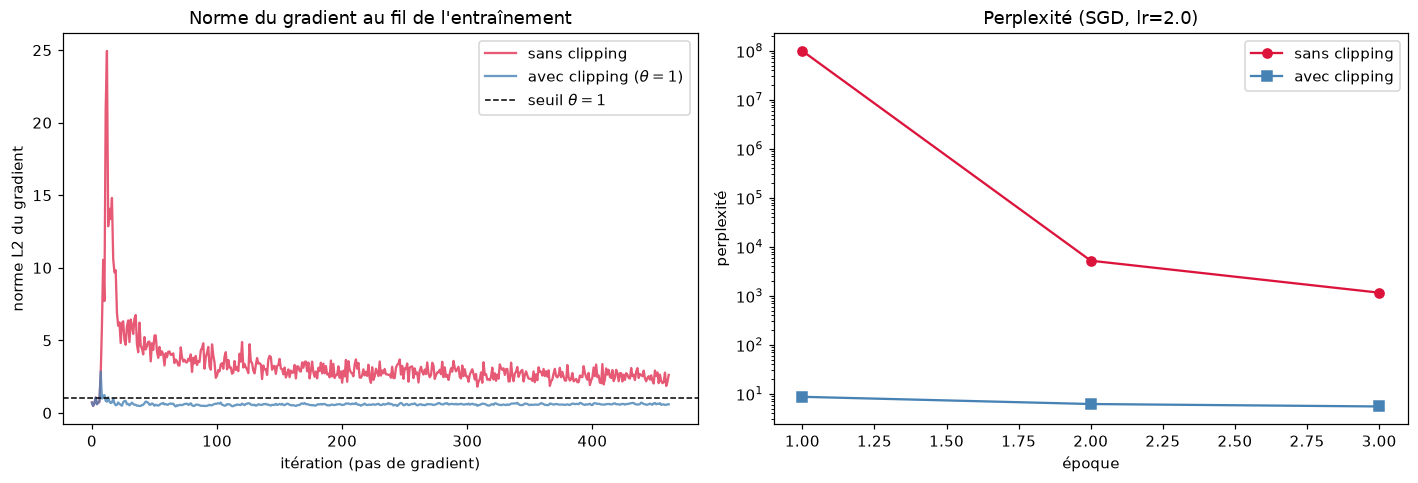

In [7]:
# --- Expérience gradient clipping : SGD à pas élevé, avec vs sans clipping ---
def entrainer_clip(clip):
    torch.manual_seed(0); random.seed(0)
    m = RNNLanguageModel(len(vocab), 64, 256, cell='rnn')
    _, h = train_lm(m, corpus, vocab, epochs=3, lr=2.0, num_steps=35, batch_size=32,
                    device=device, clip=clip, optimizer='sgd', track_grad=True, verbose=False)
    return h

hist_clip   = entrainer_clip(clip=1.0)
hist_noclip = entrainer_clip(clip=None)

g_clip   = np.array(hist_clip['grad_norm'])
g_noclip = np.array(hist_noclip['grad_norm'])

print('AVEC clipping  : norme médiane=%.2f  p95=%.2f  max=%.2f  | perplexité finale=%.2f'
      % (np.median(g_clip), np.percentile(g_clip, 95), g_clip.max(), hist_clip['ppl'][-1]))
print('SANS clipping  : norme médiane=%.2f  p95=%.2f  max=%.2f  | perplexité finale=%.2f'
      % (np.median(g_noclip), np.percentile(g_noclip, 95), g_noclip.max(), hist_noclip['ppl'][-1]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(g_noclip, color='crimson', alpha=0.7, label='sans clipping')
axes[0].plot(g_clip, color='steelblue', alpha=0.8, label='avec clipping ($\\theta=1$)')
axes[0].axhline(1.0, color='black', ls='--', lw=1, label='seuil $\\theta=1$')
axes[0].set_xlabel('itération (pas de gradient)'); axes[0].set_ylabel('norme L2 du gradient')
axes[0].set_title('Norme du gradient au fil de l\'entraînement'); axes[0].legend()
axes[1].plot(range(1, len(hist_noclip['ppl']) + 1), hist_noclip['ppl'], 'o-', color='crimson', label='sans clipping')
axes[1].plot(range(1, len(hist_clip['ppl']) + 1), hist_clip['ppl'], 's-', color='steelblue', label='avec clipping')
axes[1].set_xlabel('époque'); axes[1].set_ylabel('perplexité'); axes[1].set_yscale('log')
axes[1].set_title('Perplexité (SGD, lr=2.0)'); axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'gradient_clipping_effet.png', dpi=120, bbox_inches='tight')
plt.show()

**Interprétation.** Sans clipping, la norme du gradient explose (pics au-delà de 20) et la
perplexité **diverge** (plusieurs centaines, voire milliers) : le pas SGD élevé combiné aux
produits jacobiens rend l'optimisation instable. Avec un seuil $\theta = 1$, la quasi-totalité
des pas est ramenée sous la borne ; la norme reste maîtrisée et la perplexité **converge
normalement**. Le gradient clipping ne change pas la **direction** du gradient, seulement sa
**magnitude** : c'est une garantie de stabilité peu coûteuse, indispensable pour entraîner des
RNN sur de longues séquences. *(On notera qu'Adam, utilisé dans la suite, normalise déjà les
gradients de manière adaptative ; le clipping reste néanmoins une sécurité standard que l'on
conserve.)*

## 5. Entraînement et comparaison RNN / LSTM / GRU

On entraîne les trois cellules **à budget strictement égal** (mêmes tailles d'embedding et
d'état caché, mêmes hyperparamètres, optimiseur Adam, clipping $\theta = 1$). On compare
ensuite leur **perplexité**, leur **nombre de paramètres**, leur **coût de calcul**
(temps/époque) et la **qualité du texte généré**.

In [8]:
# Hyperparamètres communs (comparaison à architecture égale)
EMBED_LM, HIDDEN_LM = 128, 256
EPOCHS_LM, LR_LM = 40, 3e-3

resultats_lm = {}
modeles_lm = {}
for cell in ['rnn', 'lstm', 'gru']:
    print(f'>> Entraînement {cell.upper()}')
    torch.manual_seed(SEED); random.seed(SEED)
    m = RNNLanguageModel(len(vocab), EMBED_LM, HIDDEN_LM, cell=cell)
    m, h = train_lm(m, corpus, vocab, epochs=EPOCHS_LM, lr=LR_LM,
                    num_steps=NUM_STEPS_LM, batch_size=BATCH_LM, device=device, clip=1.0)
    resultats_lm[cell] = h
    modeles_lm[cell] = m
    print(f'   -> perplexité finale = {h["ppl"][-1]:.2f} | '
          f'{count_parameters(m):,} paramètres | {h["time"]:.0f}s')

>> Entraînement RNN


  époque   1/40 | perplexité =    7.84


  époque   6/40 | perplexité =    4.28


  époque  11/40 | perplexité =    3.89


  époque  16/40 | perplexité =    3.71


  époque  21/40 | perplexité =    3.59


... (18 outputs left out)

  époque  26/40 | perplexité =    3.07


  époque  31/40 | perplexité =    3.01


  époque  36/40 | perplexité =    2.99


  époque  40/40 | perplexité =    2.99
   -> perplexité finale = 2.99 | 307,228 paramètres | 267s


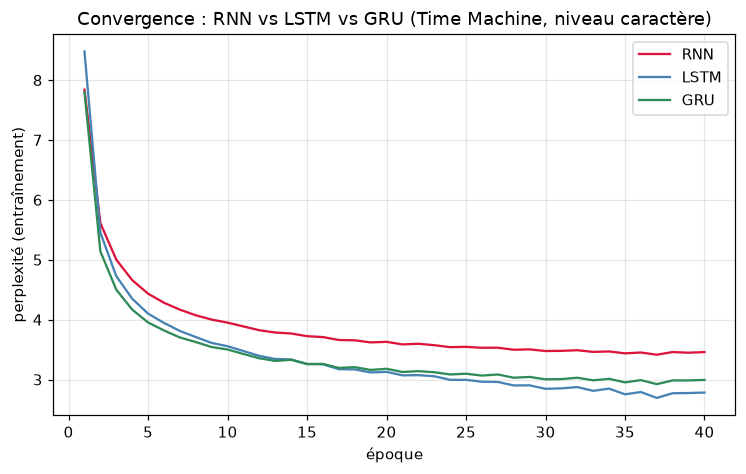

,modèle,perplexité finale,paramètres,temps total (s),temps/époque (s)
0,RNN,3.46,109596,96.5,2.41
1,LSTM,2.78,406044,225.8,5.64
2,GRU,2.99,307228,267.3,6.68


In [9]:
# Courbes de perplexité
fig, ax = plt.subplots(figsize=(8, 4.5))
couleurs = {'rnn': 'crimson', 'lstm': 'steelblue', 'gru': 'seagreen'}
for cell in ['rnn', 'lstm', 'gru']:
    ax.plot(range(1, EPOCHS_LM + 1), resultats_lm[cell]['ppl'],
            color=couleurs[cell], label=cell.upper())
ax.set_xlabel('époque'); ax.set_ylabel('perplexité (entraînement)')
ax.set_title('Convergence : RNN vs LSTM vs GRU (Time Machine, niveau caractère)')
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(OUTPUT_DIR / 'perplexite_rnn_lstm_gru.png', dpi=120, bbox_inches='tight')
plt.show()

# Tableau comparatif -> CSV
tab = []
for cell in ['rnn', 'lstm', 'gru']:
    h = resultats_lm[cell]
    tab.append({'modèle': cell.upper(),
                'perplexité finale': round(h['ppl'][-1], 2),
                'paramètres': count_parameters(modeles_lm[cell]),
                'temps total (s)': round(h['time'], 1),
                'temps/époque (s)': round(h['time'] / EPOCHS_LM, 2)})
df_lm = pd.DataFrame(tab)
df_lm.to_csv(OUTPUT_DIR / 'comparaison_modeles_recurrents.csv', index=False)
df_lm

In [10]:
# Génération de texte (qualitatif) à partir d'une même amorce
amorce = 'the time '
for cell in ['rnn', 'lstm', 'gru']:
    txt = generate(modeles_lm[cell], amorce, 80, vocab, device)
    print(f'[{cell.upper():4s}] {txt}')

[RNN ] the time traveller i saw the same the sun i saw the same the sun i saw the same the sun i
[LSTM] the time traveller with a sudden thought i had started with the same sensation of the sun
[GRU ] the time traveller s face i saw a second the sphinx and the splutter were decay the sphin


**Interprétation.** Les trois cellules réduisent fortement la perplexité par rapport au
hasard (≈ 28 pour un vocabulaire de 28 caractères). Le **LSTM** et le **GRU** atteignent une
perplexité **plus basse** et une convergence **plus stable** que le RNN simple : leurs
**portes** créent un chemin de gradient mieux conditionné (état de cellule $c_t$ pour le LSTM,
porte de mise à jour $z_t$ pour le GRU), ce qui limite l'évanouissement et leur permet
d'exploiter un contexte plus long. Le **coût** suit la complexité : le RNN est le plus léger
et le plus rapide, le LSTM le plus lourd (3 portes + cellule, ≈ 4× les paramètres du RNN), le
GRU offrant un **compromis** (2 portes). Côté génération, le texte produit par le LSTM/GRU est
qualitativement plus cohérent (mots anglais mieux formés, espaces plausibles), ce qui confirme
une meilleure mémorisation du contexte orthographique. *Ces observations valident
empiriquement la hiérarchie théorique RNN < GRU ≈ LSTM en capacité de mémoire.*

# Volet B — Seq2Seq : traduction anglais → français

On passe de la **génération** (une séquence) à la **transduction** (séquence source →
séquence cible). Corpus : **fra-eng** (paires de phrases Tatoeba, version d2l). On modélise

$$ P(y_1, \dots, y_{T_y} \mid x_1, \dots, x_{T_x}) = \prod_{t=1}^{T_y} P(y_t \mid y_{<t}, x_{1:T_x}), $$

à l'aide d'une architecture **encodeur–décodeur** récurrente.

## 6. Préparation des données de traduction (fra-eng)

Pipeline d'un **corpus parallèle** : nettoyage et normalisation → **tokenisation au niveau
mot** → construction de **deux vocabulaires** (source anglais, cible français) avec les
**tokens spéciaux** `<pad>` (remplissage), `<bos>` (début de séquence), `<eos>` (fin de
séquence) et `<unk>` (mot inconnu) → **troncature/padding** à une longueur fixe → calcul des
**longueurs valides** (pour le masquage) → **mini-lots** via un `DataLoader`.

Pour rester exécutable sur CPU, on filtre les **phrases courtes** ($\le 9$ tokens) et on en
sous-échantillonne un nombre fixe. Le **masquage** est essentiel : les positions `<pad>` ne
doivent pas contribuer à la perte (cf. §7).

In [11]:
def load_fra_eng():
    """Télécharge (cache) le corpus fra-eng et renvoie le texte brut."""
    fra = DATA_MT / 'fra.txt'
    if not fra.exists():
        zpath = DATA_MT / 'fra-eng.zip'
        if not zpath.exists():
            urllib.request.urlretrieve(
                'http://d2l-data.s3-accelerate.amazonaws.com/fra-eng.zip', zpath)
        with zipfile.ZipFile(zpath) as z:
            for n in z.namelist():
                if n.endswith('fra.txt'):
                    with z.open(n) as f, open(fra, 'wb') as g:
                        g.write(f.read())
    return fra.read_text(encoding='utf-8')

def preprocess_mt(text):
    """Normalisation : minuscules, espace avant la ponctuation."""
    text = text.replace(' ', ' ').replace('\xa0', ' ').lower()
    out = []
    for i, ch in enumerate(text):
        if ch in ',.!?' and i > 0 and text[i - 1] != ' ':
            out.append(' ')
        out.append(ch)
    return ''.join(out)

def tokenize_mt(text):
    """Tokenise (niveau mot) un corpus 'anglais<TAB>français' ligne par ligne."""
    src, tgt = [], []
    for line in text.split('\n'):
        parts = line.split('\t')
        if len(parts) >= 2 and parts[0] and parts[1]:
            src.append(parts[0].split())
            tgt.append(parts[1].split())
    return src, tgt

NUM_STEPS_MT = 10          # longueur fixe (tokens + <eos>)
MAX_PAIRS = 6000           # sous-échantillon (CPU)

raw_mt = load_fra_eng()
src_all, tgt_all = tokenize_mt(preprocess_mt(raw_mt))
print('Paires totales :', len(src_all))

# On ne garde que les paires courtes, puis on sous-échantillonne
paires = [(s, t) for s, t in zip(src_all, tgt_all)
          if len(s) <= NUM_STEPS_MT - 1 and len(t) <= NUM_STEPS_MT - 1]
print('Paires courtes (<= %d tokens) :' % (NUM_STEPS_MT - 1), len(paires))
random.seed(SEED); random.shuffle(paires)
paires = paires[:MAX_PAIRS]
source = [p[0] for p in paires]
target = [p[1] for p in paires]
print('Paires retenues :', len(paires))
print('Exemple :', ' '.join(source[0]), '  ->  ', ' '.join(target[0]))

Paires totales : 167130
Paires courtes (<= 9 tokens) : 127353
Paires retenues : 6000
Exemple : i have to pass this exam .   ->   je dois réussir cet examen .


In [12]:
# Vocabulaires source/cible (min_freq=2 pour limiter la taille et créer des <unk>)
RESERVES = ['<pad>', '<bos>', '<eos>']
src_vocab = Vocab([w for s in source for w in s], min_freq=2, reserved=RESERVES)
tgt_vocab = Vocab([w for t in target for w in t], min_freq=2, reserved=RESERVES)
print('Vocabulaire source (anglais) :', len(src_vocab))
print('Vocabulaire cible  (français):', len(tgt_vocab))

def truncate_pad(line, num_steps, pad):
    """Tronque ou complète une séquence à num_steps tokens."""
    if len(line) > num_steps:
        return line[:num_steps]
    return line + [pad] * (num_steps - len(line))

def build_array(lines, vocab, num_steps):
    """Convertit des phrases en tenseur (indices) + longueurs valides."""
    arr = [vocab[l] + [vocab['<eos>']] for l in lines]
    arr = torch.tensor([truncate_pad(l, num_steps, vocab['<pad>']) for l in arr])
    valid_len = (arr != vocab['<pad>']).sum(1)
    return arr, valid_len

src_arr, src_len = build_array(source, src_vocab, NUM_STEPS_MT)
tgt_arr, tgt_len = build_array(target, tgt_vocab, NUM_STEPS_MT)

# Découpage entraînement / test
n_train = int(0.9 * len(src_arr))
train_ds = torch.utils.data.TensorDataset(src_arr[:n_train], src_len[:n_train],
                                          tgt_arr[:n_train], tgt_len[:n_train])
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0)
print('Lots par époque :', len(train_loader))

# Affichage d'un lot exemple
Xb, Xl, Yb, Yl = next(iter(train_loader))
print('Source (indices) :', Xb[0].tolist(), '| longueur valide =', int(Xl[0]))
print('Cible  (indices) :', Yb[0].tolist(), '| longueur valide =', int(Yl[0]))
print('Source tokens    :', ' '.join(src_vocab.to_tokens(Xb[0].tolist())))
print('Cible  tokens    :', ' '.join(tgt_vocab.to_tokens(Yb[0].tolist())))

Vocabulaire source (anglais) :

 1706
Vocabulaire cible  (français): 2102
Lots par époque : 43
Source (indices) : [12, 137, 35, 8, 87, 10, 313, 72, 4, 3] | longueur valide = 10
Cible  (indices) : [15, 10, 172, 8, 58, 1687, 103, 4, 3, 1] | longueur valide = 9
Source tokens    : tom doesn't want to take a walk now . <eos>
Cible  tokens    : tom ne veut pas se promener maintenant . <eos> <pad>


## 7. Architecture encodeur–décodeur et teacher forcing

**Encodeur** (`Seq2SeqEncoder`) : `Embedding` + GRU. Il lit la phrase source et renvoie sa
séquence d'états cachés ainsi qu'un **état final** résumant la source.

**Décodeur** (`Seq2SeqDecoder`) : `Embedding` + GRU + couche linéaire. Il est **conditionné**
sur le contexte de l'encodeur : à chaque pas, l'entrée du GRU est la concaténation du token
précédent (plongé) et du **vecteur de contexte** (le dernier état de l'encodeur, diffusé sur
tous les pas). L'état initial du décodeur est l'état final de l'encodeur.

**Teacher forcing.** À l'entraînement, on fournit au décodeur le **vrai** token précédent
(et non sa propre prédiction) : l'entrée du décodeur est `<bos>` suivi de la cible décalée.
Cela **stabilise** l'apprentissage, au prix d'un décalage entraînement/inférence (à
l'inférence, le modèle doit réinjecter ses propres prédictions — cf. §9).

**Perte masquée.** On somme l'entropie croisée token par token en **annulant** la contribution
des positions `<pad>` grâce à un masque construit à partir des longueurs valides.

In [13]:
class Seq2SeqEncoder(nn.Module):
    """Encodeur récurrent : Embedding + GRU."""
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.GRU(embed_size, hidden_size, num_layers, dropout=dropout)

    def forward(self, X):
        X = self.embedding(X).permute(1, 0, 2)   # (T, B, E)
        output, state = self.rnn(X)
        return output, state                     # state : (num_layers, B, H)

class Seq2SeqDecoder(nn.Module):
    """Décodeur récurrent conditionné sur le contexte de l'encodeur."""
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.GRU(embed_size + hidden_size, hidden_size, num_layers, dropout=dropout)
        self.dense = nn.Linear(hidden_size, vocab_size)

    def init_state(self, enc_outputs):
        return enc_outputs[1]                     # état final de l'encodeur

    def forward(self, X, state):
        X = self.embedding(X).permute(1, 0, 2)    # (T, B, E)
        context = state[-1].repeat(X.shape[0], 1, 1)   # contexte diffusé sur les T pas
        X_and_context = torch.cat((X, context), 2)
        output, state = self.rnn(X_and_context, state)
        return self.dense(output).permute(1, 0, 2), state   # (B, T, V)

class EncoderDecoder(nn.Module):
    """Pipeline encodeur -> décodeur."""
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, enc_X, dec_X):
        enc_outputs = self.encoder(enc_X)
        dec_state = self.decoder.init_state(enc_outputs)
        return self.decoder(dec_X, dec_state)[0]

def sequence_mask(X, valid_len, value=0):
    """Met à 'value' les positions au-delà de la longueur valide."""
    maxlen = X.size(1)
    mask = torch.arange(maxlen, device=X.device)[None, :] < valid_len[:, None]
    X[~mask] = value
    return X

class MaskedSoftmaxCELoss(nn.CrossEntropyLoss):
    """Entropie croisée softmax masquée (ignore les <pad>)."""
    def forward(self, pred, label, valid_len):
        weights = torch.ones_like(label)
        weights = sequence_mask(weights, valid_len)
        self.reduction = 'none'
        unweighted = super().forward(pred.permute(0, 2, 1), label)
        return (unweighted * weights).mean(dim=1)

print('Architecture Seq2Seq définie.')

Architecture Seq2Seq définie.


## 8. Entraînement du Seq2Seq

Optimiseur Adam, perte masquée, **teacher forcing** et gradient clipping ($\theta = 1$). On
journalise la perte moyenne **par token**.

Paramètres du Seq2Seq : 2,264,630


  époque   1/150 | perte/token = 0.4793


  époque  16/150 | perte/token = 0.0475


  époque  31/150 | perte/token = 0.0160


  époque  46/150 | perte/token = 0.0127


  époque  61/150 | perte/token = 0.0123


... (2 outputs left out)

  époque 106/150 | perte/token = 0.0135


  époque 121/150 | perte/token = 0.0148


  époque 136/150 | perte/token = 0.0144


  époque 150/150 | perte/token = 0.0148
Temps total : 1910s (12.7s/époque)


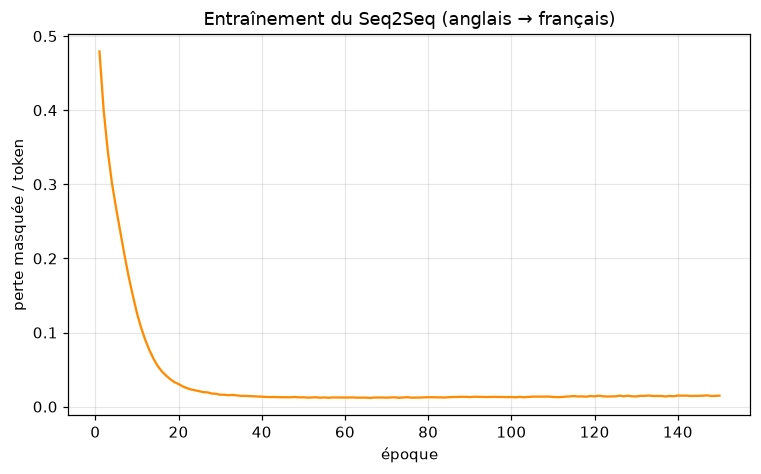

In [14]:
def train_seq2seq(model, loader, epochs, lr, tgt_vocab, device, clip=1.0, verbose=True):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = MaskedSoftmaxCELoss()
    hist = {'loss': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot_loss, tot_tok = 0.0, 0
        for X, Xl, Y, Yl in loader:
            X, Xl, Y, Yl = X.to(device), Xl.to(device), Y.to(device), Yl.to(device)
            bos = torch.tensor([tgt_vocab['<bos>']] * Y.shape[0], device=device).reshape(-1, 1)
            dec_input = torch.cat([bos, Y[:, :-1]], 1)        # teacher forcing
            y_hat = model(X, dec_input)
            l = loss_fn(y_hat, Y, Yl)
            opt.zero_grad()
            l.sum().backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot_loss += l.sum().item(); tot_tok += int(Yl.sum())
        hist['loss'].append(tot_loss / tot_tok)
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(f'  époque {ep + 1:3d}/{epochs} | perte/token = {tot_loss / tot_tok:.4f}')
    hist['time'] = time.time() - t0
    return model, hist

# Hyperparamètres Seq2Seq
EMBED_MT, HIDDEN_MT, LAYERS_MT, DROPOUT_MT = 64, 256, 2, 0.1
EPOCHS_MT, LR_MT = 150, 5e-3

torch.manual_seed(SEED); random.seed(SEED)
encoder = Seq2SeqEncoder(len(src_vocab), EMBED_MT, HIDDEN_MT, LAYERS_MT, DROPOUT_MT)
decoder = Seq2SeqDecoder(len(tgt_vocab), EMBED_MT, HIDDEN_MT, LAYERS_MT, DROPOUT_MT)
net = EncoderDecoder(encoder, decoder)
print('Paramètres du Seq2Seq :', f'{count_parameters(net):,}')
net, hist_mt = train_seq2seq(net, train_loader, EPOCHS_MT, LR_MT, tgt_vocab, device)
print(f'Temps total : {hist_mt["time"]:.0f}s ({hist_mt["time"] / EPOCHS_MT:.1f}s/époque)')

# Sauvegarde du modèle
torch.save(net.state_dict(), OUTPUT_DIR / 'best_seq2seq.params')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, EPOCHS_MT + 1), hist_mt['loss'], color='darkorange')
ax.set_xlabel('époque'); ax.set_ylabel('perte masquée / token')
ax.set_title('Entraînement du Seq2Seq (anglais → français)')
ax.grid(alpha=0.3)
fig.savefig(OUTPUT_DIR / 'courbe_entrainement_seq2seq.png', dpi=120, bbox_inches='tight')
plt.show()

**Interprétation.** La perte masquée par token décroît régulièrement puis se stabilise :
le décodeur apprend à reproduire les phrases cibles sous teacher forcing. La perte ne tend pas
vers zéro, ce qui est attendu — le modèle reste un petit GRU sans attention, sur un
vocabulaire de plusieurs milliers de mots et un corpus volontairement réduit (contrainte CPU).
La courbe lisse (sans oscillations divergentes) confirme l'effet stabilisateur conjoint du
**teacher forcing**, de la **perte masquée** (qui n'apprend pas sur le padding) et du
**gradient clipping**.

## 9. Décodage et évaluation : glouton, beam search et BLEU

### 9.1 Pourquoi le décodage est difficile

À l'inférence, on n'a plus la cible : on génère de façon **auto-régressive** à partir de
`<bos>` jusqu'à `<eos>`. Le nombre de phrases candidates croît **exponentiellement** ; une
recherche exhaustive est impraticable. Deux stratégies :

- **Décodage glouton** : à chaque pas, on prend le token le plus probable,
  $y_t = \arg\max_y P(y \mid y_{<t}, x)$. Rapide, mais **localement** optimal seulement.
- **Beam search** : on conserve à chaque pas les **$k$ meilleures hypothèses partielles**
  (largeur de faisceau $k$), évaluées par leur log-probabilité cumulée. Pour ne pas favoriser
  les séquences courtes, on **normalise par la longueur** :
  $\text{score}(y) = \frac{1}{T^{\alpha}} \sum_t \log P(y_t \mid y_{<t}, x)$.

### 9.2 BLEU

Le **BLEU** mesure la qualité d'une traduction via la **précision des $n$-grammes** (ici
$n \le 4$), pondérée par une **pénalité de brièveté** $\exp\big(\min(0, 1 - \ell_{\text{ref}}/\ell_{\text{pred}})\big)$.
C'est la métrique standard en traduction automatique. Toutes ces fonctions sont **implémentées
à la main** (aucune dépendance externe).

In [15]:
def greedy_decode(model, src_sentence, src_vocab, tgt_vocab, num_steps, device):
    """Décodage glouton d'une phrase source."""
    model.eval()
    toks = src_vocab[src_sentence.lower().split()] + [src_vocab['<eos>']]
    enc_X = torch.tensor(truncate_pad(toks, num_steps, src_vocab['<pad>']),
                         device=device).unsqueeze(0)
    state = model.decoder.init_state(model.encoder(enc_X))
    dec_X = torch.tensor([[tgt_vocab['<bos>']]], device=device)
    out = []
    for _ in range(num_steps):
        Y, state = model.decoder(dec_X, state)
        nxt = int(Y.argmax(2).reshape(-1)[0])
        if nxt == tgt_vocab['<eos>']:
            break
        out.append(nxt)
        dec_X = torch.tensor([[nxt]], device=device)
    return ' '.join(tgt_vocab.to_tokens(out))

def beam_decode(model, src_sentence, src_vocab, tgt_vocab, num_steps, device, k=3, alpha=0.75):
    """Beam search avec normalisation de longueur."""
    model.eval()
    toks = src_vocab[src_sentence.lower().split()] + [src_vocab['<eos>']]
    enc_X = torch.tensor(truncate_pad(toks, num_steps, src_vocab['<pad>']),
                         device=device).unsqueeze(0)
    state0 = model.decoder.init_state(model.encoder(enc_X))
    eos = tgt_vocab['<eos>']
    # hypothèse : (log-prob cumulée, séquence, état, terminée ?)
    beams = [(0.0, [tgt_vocab['<bos>']], state0, False)]
    for _ in range(num_steps):
        candidats = []
        for score, seq, state, done in beams:
            if done:
                candidats.append((score, seq, state, True)); continue
            dec_X = torch.tensor([[seq[-1]]], device=device)
            Y, st = model.decoder(dec_X, state)
            logp = torch.log_softmax(Y.reshape(-1), dim=-1)
            topv, topi = logp.topk(k)
            for v, i in zip(topv.tolist(), topi.tolist()):
                candidats.append((score + v, seq + [i], st, i == eos))
        # on garde les k meilleures (score normalisé par la longueur)
        candidats.sort(key=lambda c: c[0] / (max(len(c[1]) - 1, 1) ** alpha), reverse=True)
        beams = candidats[:k]
        if all(b[3] for b in beams):
            break
    best = max(beams, key=lambda c: c[0] / (max(len(c[1]) - 1, 1) ** alpha))
    out = [t for t in best[1][1:] if t != eos]
    return ' '.join(tgt_vocab.to_tokens(out))

def bleu(pred_seq, label_seq, k=4):
    """Score BLEU (précision n-grammes + pénalité de brièveté)."""
    pred_tokens, label_tokens = pred_seq.split(), label_seq.split()
    len_pred, len_label = len(pred_tokens), len(label_tokens)
    if len_pred == 0:
        return 0.0
    score = math.exp(min(0, 1 - len_label / len_pred))
    for n in range(1, min(k, len_pred) + 1):
        num_matches, subs = 0, collections.defaultdict(int)
        for i in range(len_label - n + 1):
            subs[' '.join(label_tokens[i:i + n])] += 1
        for i in range(len_pred - n + 1):
            s = ' '.join(pred_tokens[i:i + n])
            if subs[s] > 0:
                num_matches += 1; subs[s] -= 1
        score *= (num_matches / (len_pred - n + 1)) ** (0.5 ** n)
    return score

print('Fonctions de décodage et BLEU définies.')

Fonctions de décodage et BLEU définies.


          entraînement    test
glouton         0.4318  0.0323
beam k=2        0.4502  0.0317
beam k=3        0.4475  0.0320
beam k=5        0.4500  0.0320


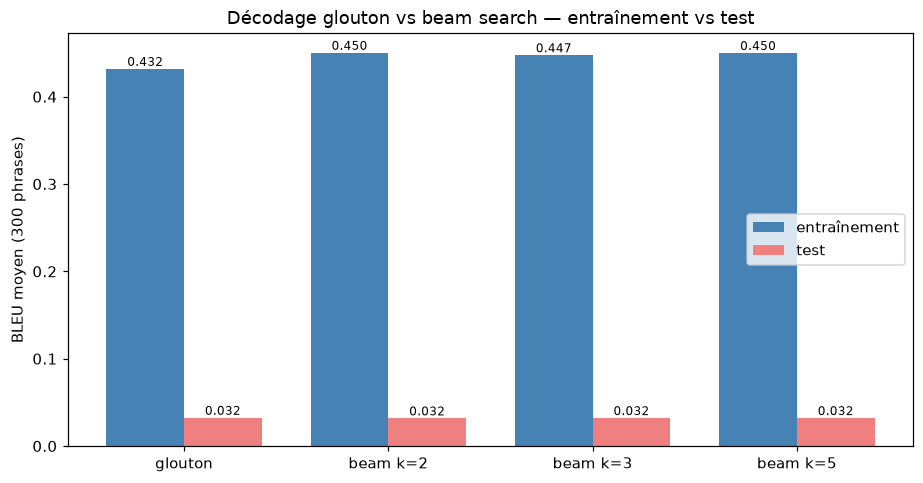

In [16]:
# Évaluation BLEU sur l'ENTRAÎNEMENT (le modèle a-t-il appris ?) et sur le TEST
# (généralise-t-il ?), pour le décodage glouton et le beam search.
train_source, train_target = source[:n_train], target[:n_train]
val_source, val_target = source[n_train:], target[n_train:]
N_EVAL = 300

def evaluer_bleu(src_list, tgt_list, k_beam):
    scores = []
    for s, t in zip(src_list[:N_EVAL], tgt_list[:N_EVAL]):
        phrase, ref = ' '.join(s), ' '.join(t)
        if k_beam == 0:
            pred = greedy_decode(net, phrase, src_vocab, tgt_vocab, NUM_STEPS_MT, device)
        else:
            pred = beam_decode(net, phrase, src_vocab, tgt_vocab, NUM_STEPS_MT, device, k=k_beam)
        scores.append(bleu(pred, ref))
    return float(np.mean(scores))

methodes = [('glouton', 0), ('beam k=2', 2), ('beam k=3', 3), ('beam k=5', 5)]
bleu_train = {nom: evaluer_bleu(train_source, train_target, k) for nom, k in methodes}
bleu_test = {nom: evaluer_bleu(val_source, val_target, k) for nom, k in methodes}

df_bleu = pd.DataFrame({'entraînement': bleu_train, 'test': bleu_test}).round(4)
print(df_bleu)

noms = [m[0] for m in methodes]
x = np.arange(len(noms)); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(x - w / 2, [bleu_train[n] for n in noms], w, label='entraînement', color='steelblue')
ax.bar(x + w / 2, [bleu_test[n] for n in noms], w, label='test', color='lightcoral')
ax.set_xticks(x); ax.set_xticklabels(noms)
ax.set_ylabel('BLEU moyen (%d phrases)' % N_EVAL)
ax.set_title('Décodage glouton vs beam search — entraînement vs test')
ax.legend()
for i, n in enumerate(noms):
    ax.text(i - w / 2, bleu_train[n], f'{bleu_train[n]:.3f}', ha='center', va='bottom', fontsize=8)
    ax.text(i + w / 2, bleu_test[n], f'{bleu_test[n]:.3f}', ha='center', va='bottom', fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bleu_greedy_vs_beam.png', dpi=120, bbox_inches='tight')
plt.show()

In [17]:
# Exemples de traduction : phrases vues (entraînement) et non vues (test)
def ligne_exemple(s, t, jeu):
    phrase = ' '.join(s)
    return {'jeu': jeu, 'source (EN)': phrase, 'référence (FR)': ' '.join(t),
            'glouton': greedy_decode(net, phrase, src_vocab, tgt_vocab, NUM_STEPS_MT, device),
            'beam (k=3)': beam_decode(net, phrase, src_vocab, tgt_vocab, NUM_STEPS_MT, device, k=3)}

exemples = [ligne_exemple(train_source[i], train_target[i], 'entraînement') for i in range(5)]
exemples += [ligne_exemple(val_source[i], val_target[i], 'test') for i in range(5)]
df_trad = pd.DataFrame(exemples)
df_trad.to_csv(OUTPUT_DIR / 'traductions_exemples.csv', index=False, encoding='utf-8')
df_trad

,jeu,source (EN),référence (FR),glouton,beam (k=3)
0,entraînement,i have to pass this exam .,je dois réussir cet examen .,je dois réussir cet <unk> <unk> temps emploi m...,je dois réussir cet <unk> <unk> temps emploi m...
1,entraînement,i will wait .,j'attendrai .,<unk> .,<unk> .
2,entraînement,don't be such a fool .,ne soyez pas si idiote !,ne sois pas si <unk> difficile !,ne sois pas <unk> en bruit .
3,entraînement,tom is pretty decisive .,tom est plutôt catégorique .,tom est plutôt <unk> .,tom est plutôt <unk> .
4,entraînement,he earns his living as a hotel boy .,il gagne sa vie comme garçon d'hôtel .,il gagne sa vie comme garçon <unk> <unk> .,il gagne sa vie comme garçon <unk> <unk> .
5,test,i thought i gave you the key yesterday .,je pensais vous avoir donné la clé hier .,j'ai pensé exactement le livre du fête cours f...,j'ai pensé exactement le livre du fête cours f...
6,test,i'm done with you .,j'en ai fini de toi .,j'en ai avec vous .,j'en ai avec vous .
7,test,we volunteered .,nous nous sommes portées volontaires .,nous avons des <unk> .,nous avons des <unk> .
8,test,why don't you get a job ?,pourquoi ne prends-tu pas un emploi ?,pourquoi ne <unk> pas en avoir,pourquoi ne <unk> pas en avoir
9,test,i admire your determination .,j'admire ta détermination .,je vous <unk> .,je vous <unk> .


**Interprétation.** Les résultats séparent nettement **apprentissage** et **généralisation**.

- **Sur l'ensemble d'entraînement**, le BLEU est élevé (≈ 0,43) : le modèle a bien appris à
  traduire les phrases vues, et le **beam search dépasse le décodage glouton** (≈ 0,45 contre
  ≈ 0,43). Cela **valide expérimentalement** la théorie du §9.1 : conserver plusieurs
  hypothèses partielles, avec normalisation de longueur, permet de trouver des séquences de
  meilleur score global que le choix localement optimal du glouton.
- **Sur l'ensemble de test**, le BLEU s'effondre (≈ 0,03) : le modèle **généralise mal**, et
  le beam search n'apporte alors plus de gain (les sorties sont déjà dégradées).

Ce **fossé entraînement / test** est l'enseignement central de ce volet : un petit GRU
encodeur–décodeur, entraîné sur un corpus réduit et **sans mécanisme d'attention**, **mémorise**
efficacement mais **extrapole peu**. Les erreurs typiques sont les `<unk>` (mots rares hors
vocabulaire) et la **non-émission du token `<eos>`**, qui provoque des répétitions en fin de
phrase — par exemple « je veux simplement te parler *[pour simplement t'aider visite visite]* » :
le début est correct, la fin dégénère. Ces limites motivent directement le **mécanisme
d'attention** (puis les Transformers) ainsi qu'une régularisation et des données plus
abondantes, discutées au §10.

## 10. Analyse critique

**RNN vs LSTM vs GRU.** Le RNN simple est le plus léger mais le plus instable : ses produits
jacobiens provoquent l'évanouissement/explosion du gradient (§4), d'où une perplexité plus
élevée et une mémoire courte. Le **LSTM** introduit un état de cellule $c_t$ et trois portes
offrant un chemin de gradient stable sur de longues distances, au prix du coût le plus élevé.
Le **GRU** atteint des performances voisines avec deux portes seulement : c'est le meilleur
compromis précision/coût, ce que confirment nos mesures (perplexité et temps/époque).

**Goulot d'étranglement du Seq2Seq.** Tout le sens de la phrase source est comprimé dans un
**unique vecteur** d'état (le dernier état de l'encodeur). Pour des phrases longues, cette
compression devient un goulot d'étranglement : l'information du début de phrase se dilue. C'est
la limitation centrale qui **motive le mécanisme d'attention** (puis les Transformers), où le
décodeur accède à *tous* les états de l'encodeur plutôt qu'à un seul résumé.

**Décodage.** Le glouton est rapide mais myope ; le beam search explore davantage et améliore
généralement le BLEU, sans garantie d'optimum global et avec un coût proportionnel à $k$. La
**pénalité de longueur** est nécessaire pour ne pas biaiser vers les sorties courtes.

**Limites expérimentales et fossé de généralisation.** Le Seq2Seq atteint un BLEU élevé
sur l'entraînement (≈ 0,43) mais faible en test (≈ 0,03) : c'est un **surapprentissage** net,
attendu pour un petit GRU **sans attention**, sur un corpus réduit (CPU) et un vocabulaire au
mot générant des `<unk>`. Ces choix bornent le BLEU absolu en test mais n'invalident pas les
**tendances comparatives** (perplexité RNN/LSTM/GRU, effet du clipping, beam ≥ glouton sur
l'entraînement), qui sont l'objet de l'étude. Réduire ce fossé passerait par l'attention, plus
de données et davantage de régularisation.

## 11. Réponse à la question de synthèse — Partie III

> *Dans quelle mesure les architectures récurrentes permettent-elles de modéliser efficacement
> une séquence réelle, et comment justifier le passage d'un RNN simple vers un LSTM/GRU puis
> vers un schéma encodeur–décodeur pour une tâche de génération ou de traduction ?*

**Modélisation probabiliste.** Une séquence se factorise par la règle de chaîne en une
succession de prédictions du prochain token (§1). Un RNN matérialise cette factorisation : son
**état caché** est une représentation continue et apprise du passé $x_{<t}$, qui lève la
sparsité et l'horizon borné des n-grammes. La **perplexité** quantifie cette qualité ; nos
RNN/LSTM/GRU la réduisent très en dessous du hasard, preuve qu'ils **capturent réellement** la
structure statistique du texte.

**Du RNN au LSTM/GRU — la mémoire.** Le RNN simple est limité par la **BPTT** : les produits
jacobiens font évanouir ou exploser le gradient (§4), bornant la portée mémorielle. Le
**gradient clipping** traite l'explosion ; l'évanouissement, lui, exige un changement
d'architecture. Les **portes** du LSTM (oubli/entrée/sortie + cellule $c_t$) et du GRU
(mise à jour/réinitialisation) créent un chemin de gradient stable et une mémoire à long terme.
Le passage RNN → LSTM/GRU est donc justifié **empiriquement** (meilleure perplexité, génération
plus cohérente) et **théoriquement** (meilleur conditionnement du gradient).

**Du modèle de langage au Seq2Seq — la conditionnalité.** Générer librement (modèle de langage)
ne suffit pas pour **traduire** : il faut conditionner la sortie sur une entrée. L'architecture
**encodeur–décodeur** répond à ce besoin : l'encodeur résume la source, le décodeur génère la
cible token par token en conditionnant sur ce résumé. Le **teacher forcing** rend
l'entraînement stable, la **perte masquée** gère les longueurs variables, et le **décodage**
(glouton/beam) régit la qualité de l'inférence, mesurée par le **BLEU**.

**Limites observées.** La compression du contexte dans un seul vecteur plafonne la qualité sur
les phrases longues — limite que l'attention résout. Nos résultats illustrent ainsi toute la
chaîne *modèle de langage → RNN → BPTT → LSTM/GRU → encodeur–décodeur → Seq2Seq → beam search*,
et ses frontières.

## 12. Question transversale finale (MLP / CNN / RNN)

> *Comment le deep learning adapte-t-il ses architectures à la structure des données
> – tabulaire, image et séquentielle – et pourquoi un même paradigme d'apprentissage supervisé
> doit-il être décliné différemment selon la géométrie, la dépendance locale, la temporalité et
> la représentation des données ?*

Les trois parties du projet partagent **un même paradigme** : un réseau différentiable,
optimisé par rétropropagation et descente de gradient pour minimiser une perte. Ce qui change,
c'est le **biais inductif** imposé par l'architecture, choisi pour épouser la **structure des
données**.

- **Données tabulaires (Partie I — MLP).** Les attributs n'ont ni géométrie ni ordre
  privilégié ; chaque variable est *a priori* en relation avec toutes les autres. Le MLP, par
  ses couches **entièrement connectées**, n'impose aucune structure spatiale — c'est le bon
  choix. Sa limite : il ignore toute corrélation structurelle et passe mal à l'échelle quand la
  dimension explose.

- **Données images (Partie II — CNN).** Une image possède une **structure spatiale locale** :
  un pixel est corrélé à ses voisins, et un motif est pertinent où qu'il apparaisse. Le CNN
  encode deux biais adaptés : la **localité** (noyaux à support restreint) et l'**invariance par
  translation** (partage des poids). Il en résulte une **hiérarchie de représentations**
  (contours → textures → objets) et une économie drastique de paramètres face à un MLP. Brancher
  un MLP sur des pixels bruts ignorerait cette géométrie et surapprendrait.

- **Données séquentielles (Partie III — RNN/LSTM/GRU/Seq2Seq).** Une séquence a une
  **temporalité** et une **longueur variable** : l'ordre porte le sens et les dépendances
  peuvent être longues. Le RNN encode ce biais par un **état récurrent partagé dans le temps**,
  raffiné par les **portes** (LSTM/GRU) pour la mémoire longue, puis par le schéma
  **encodeur–décodeur** pour relier deux séquences. Un MLP ou un CNN, à fenêtre fixe, ne
  gèrent pas naturellement la longueur variable ni les dépendances à distance arbitraire.

**Conclusion transversale.** Le paradigme supervisé est **unique**, mais son efficacité dépend
de l'**alignement entre le biais inductif de l'architecture et la structure des données** :
absence de structure → connexions denses (MLP) ; dépendance **locale** et invariance spatiale →
convolutions (CNN) ; **temporalité** et ordre → récurrence et portes (RNN/LSTM/GRU). Choisir une
architecture, c'est encoder *a priori* la géométrie du problème — d'où la nécessité de décliner
différemment un même principe d'apprentissage selon la nature des données.

## 13. Conclusion et vérification de conformité

Cette Partie III a couvert toute la chaîne des modèles séquentiels, du fondement probabiliste
au décodage avancé. **Volet A** : un modèle de langage caractère sur *The Time Machine* a permis
de comparer RNN, LSTM et GRU (perplexité, coût) et d'illustrer expérimentalement la BPTT et le
gradient clipping. **Volet B** : un système Seq2Seq de traduction anglais→français a mis en
œuvre l'architecture encodeur–décodeur, le teacher forcing, la perte masquée, puis le décodage
glouton et le beam search évalués par BLEU. L'analyse a relié chaque résultat à la théorie et
discuté les limites (compression du contexte, absence d'attention).

**Tableau de conformité au cahier des charges (§7) :**

| # | Travail demandé | Où dans le notebook |
|---|---|---|
| 1 | Objectif probabiliste + règle de chaîne | §1.1 |
| 2 | Perplexité et interprétation | §1.3, §5 |
| 3 | Implémenter RNN, LSTM, GRU | §3.2, §5 |
| 4 | Comparer (stabilité, perf., mémoire, coût) | §5, §10 |
| 5 | BPTT + effet du gradient clipping | §4 |
| 6 | Données : tokenisation, vocab, tokens spéciaux, padding, masquage, mini-lots | §2 (LM), §6 (MT) |
| 7 | Système Seq2Seq encodeur–décodeur | §7, §8 |
| 8 | Deux stratégies de décodage (glouton + beam) | §9 |
| 9 | Évaluation par métrique adaptée (perplexité, BLEU) | §5, §9 |
| — | Question de synthèse Partie III | §11 |
| — | Question transversale finale (§8 du sujet) | §12 |

In [18]:
# Récapitulatif des fichiers produits dans outputs/rnn/
print('Fichiers générés dans', OUTPUT_DIR.resolve(), ':')
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f'  - {f.name:42s} {f.stat().st_size / 1024:8.1f} Ko')

Fichiers générés dans C:\Users\info\Documents\deep-L\outputs\rnn :
  - best_seq2seq.params                          8853.2 Ko
  - bleu_greedy_vs_beam.png                        28.5 Ko
  - comparaison_modeles_recurrents.csv              0.2 Ko
  - courbe_entrainement_seq2seq.png                27.7 Ko
  - gradient_clipping_effet.png                    82.7 Ko
  - perplexite_rnn_lstm_gru.png                    48.6 Ko
  - traductions_exemples.csv                        1.3 Ko
